# 05 — Visualização Grand-Average, Seleção de Características e Tuning de SVM no BETA

> **Adaptação de:** `SSVEP/tunning.ipynb` e `SomeFeatures/05-viz_selection.ipynb` ([bneurd/tutoriais](https://github.com/bneurd/tutoriais)).

Este notebook fecha o ciclo completo de preparação pedido pelo professor antes de iniciarmos os modelos profundos do projeto:
1. **Visualização Grand-Average (`S1` a `S10`):** Reproduz as células finais de `tunning.ipynb` tirando a média dos 10 participantes, dos 4 blocos e dos 9 eletrodos occipitais (`PZ, PO5, PO3, POZ, PO4, PO6, O1, OZ, O2`), removendo o trecho basal e plotando os espectros FFT com linha tracejada vermelha nos alvos;
2. **Projeção 2D com PCA (`05-viz_selection.ipynb`):** Visualiza a separabilidade espacial das classes reduzindo a dimensionalidade via PCA;
3. **Seleção de Características (`VarianceThreshold`, `SelectKBest`, `SelectPercentile`, `RFE`) + `SVM`:** Compara todos os seletores sugeridos em `tunning.ipynb` usando validação cruzada por blocos (*Leave-One-Block-Out*, 4 folds);
4. **Tuning de Hiperparâmetros (`GridSearchCV`) e Comparativo de Canais (`64ch vs 9ch vs 5ch vs 3ch`) nos 10 Voluntários (`S1..S10`)!**

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from src.bneurd_beta import (
    BETA_SORTED_FREQS,
    CHANNEL_PRESETS,
    butter_bandpass,
    butter_notch,
    evaluate_selectors_and_svm,
    extract_beta_ml_features,
    load_beta_subject,
    tune_svm_hyperparameters,
)

### 1. Visualização Grand-Average SSVEP nos 10 Voluntários (`S1` a `S10`)
Adaptando fielmente `tunning.ipynb` (células 6 a 9) para os nossos arquivos locais `data/raw/S1.mat..S10.mat`:

Shape empilhado (suj, blocos, alvos, canais, tempo): (10, 4, 40, 9, 467)
Shape médio final (40 alvos, tempo): (40, 467)


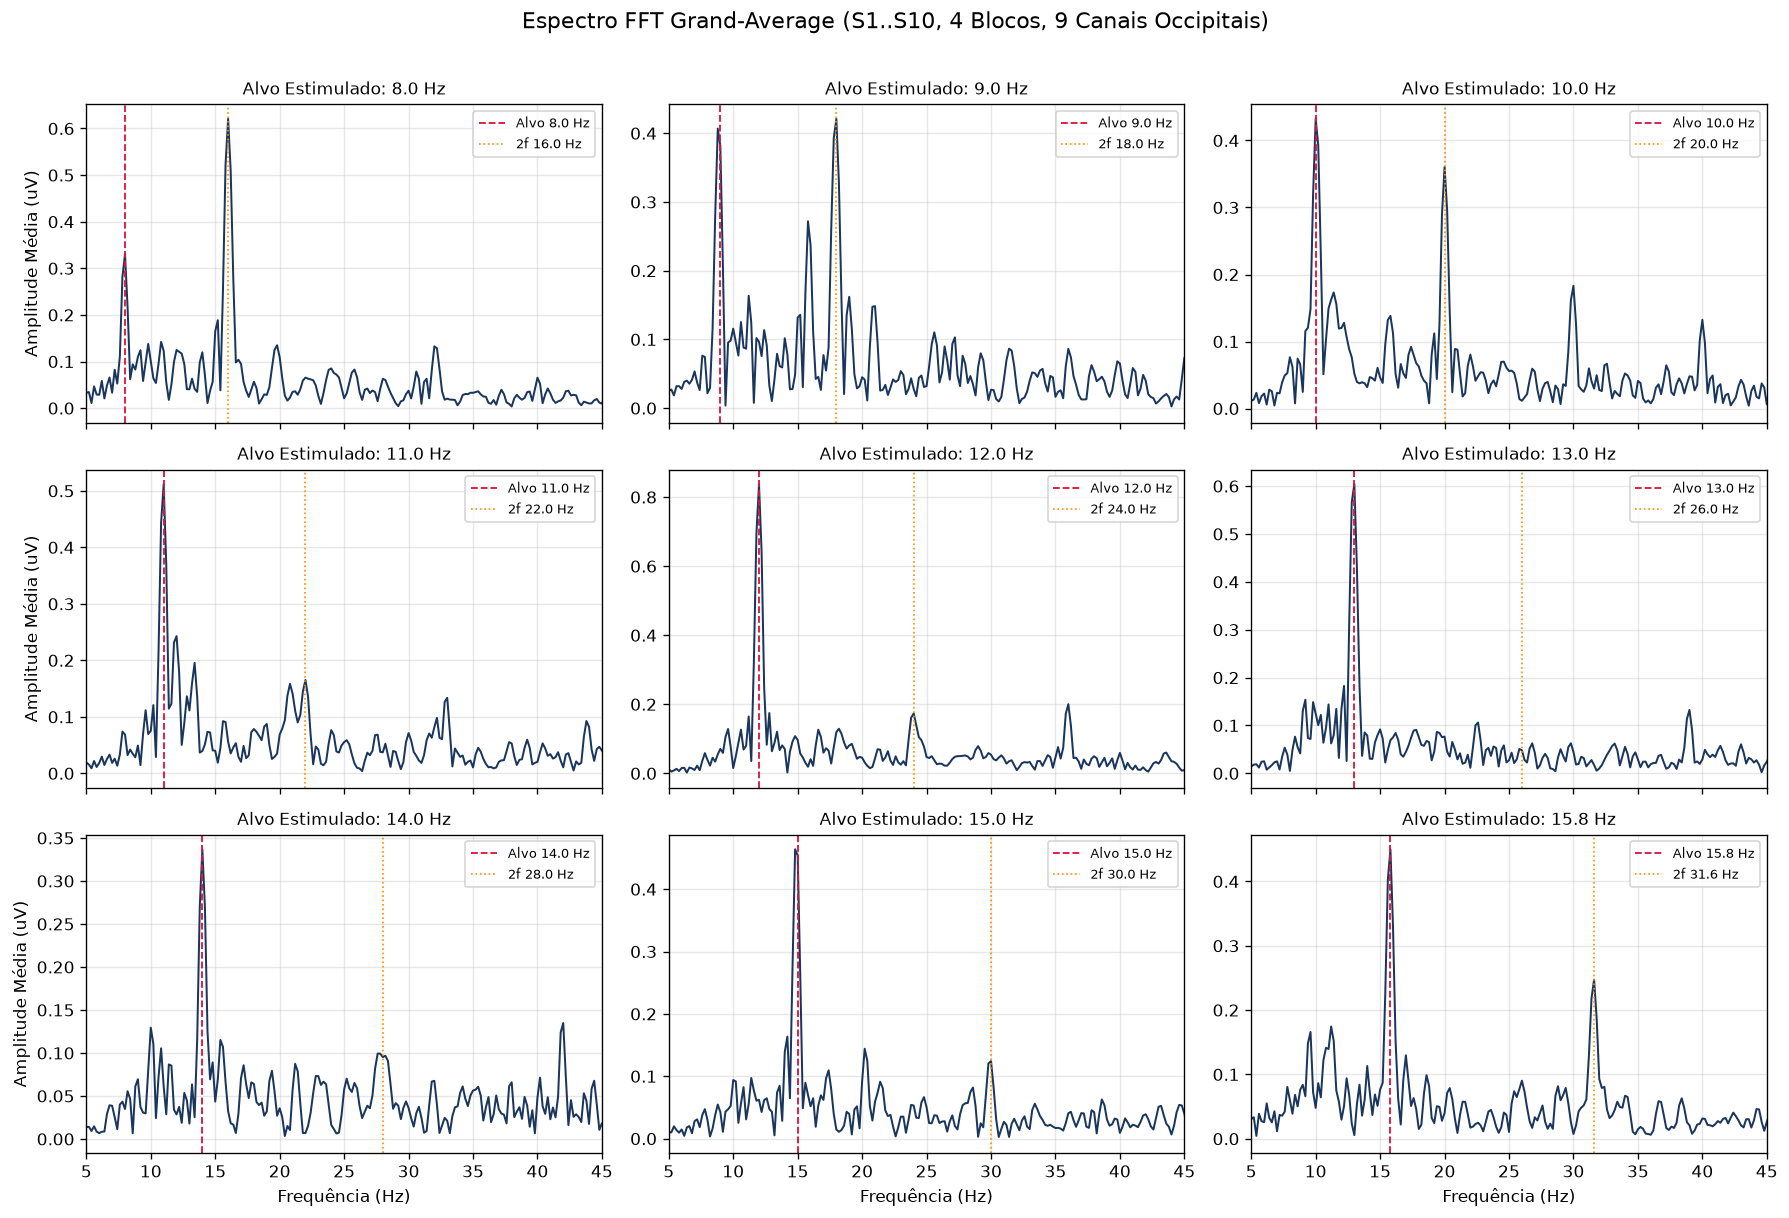

In [2]:
# Empilha os 10 participantes já nos 9 eletrodos occipitais e sem a parte basal (0.63s a 2.5s)
group_trials = []
for sub_id in range(1, 11):
    X_sub, y_f, y_c, blk, meta = load_beta_subject(sub_id, channels="9ch", window="stim_latency")
    X_sub_filt = butter_bandpass(butter_notch(X_sub, 50.0, fs=250), 8.0, 64.0, fs=250)
    # Reorganiza (160, 9, T) -> (4 blocos, 40 alvos, 9 canais, T)
    group_trials.append(X_sub_filt.reshape(4, 40, 9, -1))

eeg_group = np.array(group_trials)  # (10 sujeitos, 4 blocos, 40 alvos, 9 canais, T)
eeg_avg = eeg_group.mean(axis=(0, 1, 3))  # Média dos sujeitos, blocos e 9 canais -> (40, T)
print("Shape empilhado (suj, blocos, alvos, canais, tempo):", eeg_group.shape)
print("Shape médio final (40 alvos, tempo):", eeg_avg.shape)

# Plota grade 3x3 com 9 frequências representativas distribuídas entre 8.0 e 15.8 Hz
sample_indices = [0, 5, 10, 15, 20, 25, 30, 35, 39]
freqs_fft = np.fft.rfftfreq(1250, d=1.0 / 250.0)
w_fft = np.abs(np.fft.rfft(eeg_avg, n=1250, axis=-1)) / eeg_avg.shape[-1]

fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax, idx_t in zip(axes.flatten(), sample_indices):
    target_hz = BETA_SORTED_FREQS[idx_t]
    ax.plot(freqs_fft, w_fft[idx_t], color="#1a365d", linewidth=1.2)
    ax.axvline(target_hz, linestyle="--", linewidth=1.1, color="crimson", label=f"Alvo {target_hz:.1f} Hz")
    ax.axvline(2 * target_hz, linestyle=":", linewidth=1.0, color="darkorange", label=f"2f {2*target_hz:.1f} Hz")
    ax.set_xlim(5, 45)
    ax.set_title(f"Alvo Estimulado: {target_hz:.1f} Hz", fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")

for ax in axes[-1, :]:
    ax.set_xlabel("Frequência (Hz)")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitude Média (uV)")

plt.suptitle("Espectro FFT Grand-Average (S1..S10, 4 Blocos, 9 Canais Occipitais)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 2. Visualização Bidimensional com PCA (`SomeFeatures/05-viz_selection.ipynb`)
Conforme sugerido no tutorial `05-viz_selection.ipynb`, reduzimos os múltiplos canais/características a 2 componentes principais via `PCA` para visualizar o agrupamento das classes (exibindo 6 frequências bem espaçadas do participante `S1` para clareza visual):

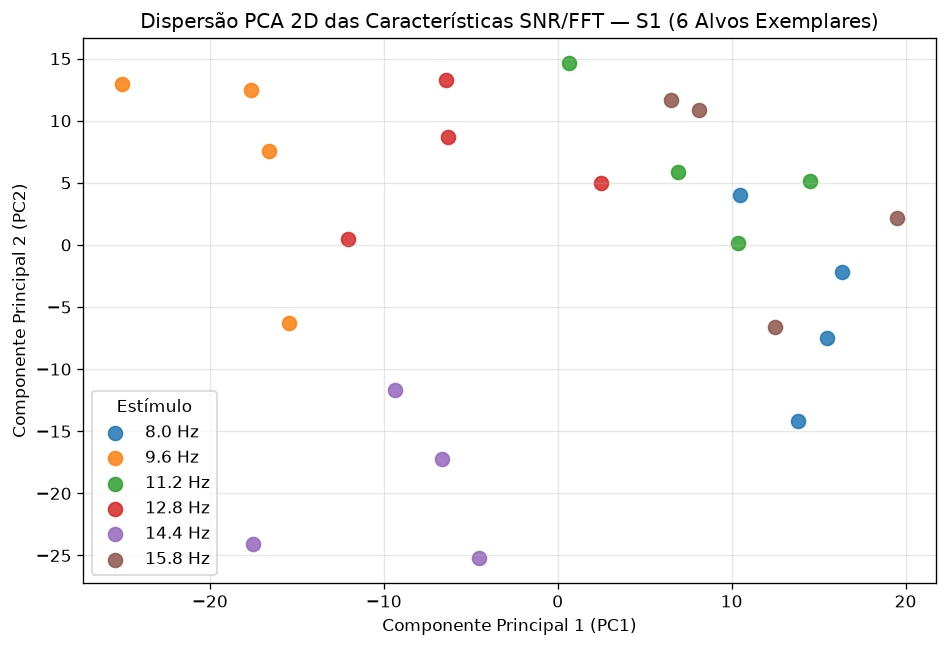

In [3]:
X_s1_9, y_f_s1, y_cls_s1, blocks_s1, _ = load_beta_subject(1, channels="9ch", window="full")
X_s1_9_filt = butter_bandpass(butter_notch(X_s1_9, 50.0, fs=250), 8.0, 64.0, fs=250)
feats_s1_9 = extract_beta_ml_features(X_s1_9_filt)["feature_matrix"]

subset_freqs = [8.0, 9.6, 11.2, 12.8, 14.4, 15.8]
mask_sub = np.isin(np.round(y_f_s1, 1), subset_freqs)
X_pca_2d = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(feats_s1_9[mask_sub]))

fig, ax = plt.subplots(figsize=(8, 5.5))
for f_val in subset_freqs:
    pts = X_pca_2d[np.isclose(y_f_s1[mask_sub], f_val)]
    ax.scatter(pts[:, 0], pts[:, 1], s=70, alpha=0.85, label=f"{f_val:.1f} Hz")

ax.set_title("Dispersão PCA 2D das Características SNR/FFT — S1 (6 Alvos Exemplares)")
ax.set_xlabel("Componente Principal 1 (PC1)")
ax.set_ylabel("Componente Principal 2 (PC2)")
ax.legend(title="Estímulo")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Seleção de Características (`VarianceThreshold`, `SelectKBest`, `SelectPercentile`, `RFE`) + Classificador `SVM`
Comparamos em `S1` a matriz completa de **64 canais** (`10.240` características, onde muitos canais frontais/temporais contêm apenas ruído!) contra os seletores de características e a seleção espacial nos **9 canais occipitais** (`1.440` características):

In [4]:
X_s1_64, _, _, _, _ = load_beta_subject(1, channels="all", window="full")
X_s1_64_filt = butter_bandpass(butter_notch(X_s1_64, 50.0, fs=250), 8.0, 64.0, fs=250)
feats_s1_64 = extract_beta_ml_features(X_s1_64_filt)["feature_matrix"]

res_64 = evaluate_selectors_and_svm(feats_s1_64, y_cls_s1, blocks=blocks_s1, k_best=240, percentile=10, rfe_features=200)
res_9 = evaluate_selectors_and_svm(feats_s1_9, y_cls_s1, blocks=blocks_s1, k_best=240, percentile=25, rfe_features=200)

print("=== Resultados S1 — 64 Canais Completos (10.240 features) ===")
for k, v in res_64.items():
    print(f"  {k:32s}: {v:6.2f}%")

print("\n=== Resultados S1 — 9 Canais Parieto-Occipitais (1.440 features) ===")
for k, v in res_9.items():
    print(f"  {k:32s}: {v:6.2f}%")

=== Resultados S1 — 64 Canais Completos (10.240 features) ===
  SVM Puro (Sem Seleção)          :  28.75%
  VarianceThreshold + SVM         :  28.75%
  SelectKBest (k=240) + SVM       :  79.38%
  SelectPercentile (10%) + SVM    :  75.62%
  RFE (n=200) + SVM               :  70.00%

=== Resultados S1 — 9 Canais Parieto-Occipitais (1.440 features) ===
  SVM Puro (Sem Seleção)          :  63.13%
  VarianceThreshold + SVM         :  63.13%
  SelectKBest (k=240) + SVM       :  80.62%
  SelectPercentile (25%) + SVM    :  81.88%
  RFE (n=200) + SVM               :  73.75%


### 4. Tuning do `SVM` (`GridSearchCV`) e Avaliação nos 10 Voluntários (`S1..S10`) Variando Canais (`64 vs 9 vs 5 vs 3`)
Realizamos o ajuste fino de hiperparâmetros (`C`, `kernel`, `k`) e avaliamos todos os 10 voluntários baixados, conectando diretamente o tutorial preliminar do BNEURD à questão central da nossa pesquisa em OPT098!

Melhor configuração SVM após Tuning em S1 (9ch): 80.62% | params={'select__k': 240, 'svm__C': 0.1, 'svm__kernel': 'linear'}

=== Benchmark Final SVM + SelectKBest (Tuned) nos 10 Sujeitos (S1..S10) ===
  Configuração  all | Média:  45.94% ± 22.90% | Min: 11.88% | Max: 79.38%
  Configuração  9ch | Média:  42.12% ± 25.89% | Min: 10.00% | Max: 80.62%
  Configuração  5ch | Média:  42.06% ± 24.98% | Min:  8.75% | Max: 80.62%
  Configuração  3ch | Média:  37.94% ± 27.15% | Min: 11.88% | Max: 80.00%


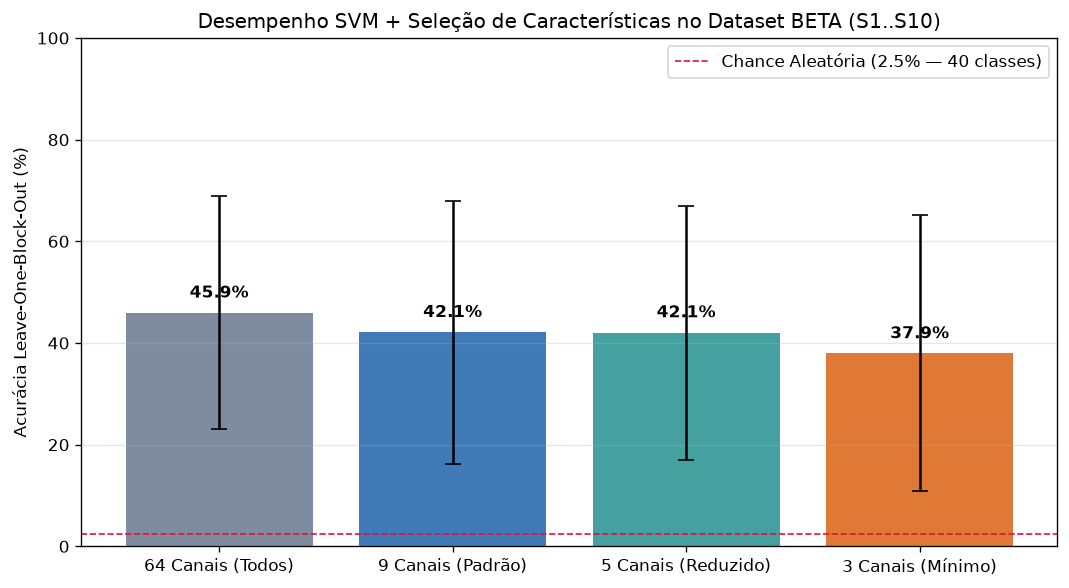

In [5]:
best_params, best_acc_s1, _ = tune_svm_hyperparameters(feats_s1_9, y_cls_s1, blocks_s1, k_features=240)
print(f"Melhor configuração SVM após Tuning em S1 (9ch): {best_acc_s1:.2f}% | params={best_params}")

channel_configs = ["all", "9ch", "5ch", "3ch"]
svm_bench = {cfg: [] for cfg in channel_configs}

for sub_id in range(1, 11):
    X_all, _, y_c, blk, _ = load_beta_subject(sub_id, channels="all", window="full")
    X_all_filt = butter_bandpass(butter_notch(X_all, 50.0, fs=250), 8.0, 64.0, fs=250)

    for cfg in channel_configs:
        ch_idx = list(range(64)) if cfg == "all" else CHANNEL_PRESETS[cfg]
        f_mat = extract_beta_ml_features(X_all_filt[:, ch_idx, :])["feature_matrix"]
        _, best_sub_acc, _ = tune_svm_hyperparameters(f_mat, y_c, blk, k_features=min(240, f_mat.shape[1]))
        svm_bench[cfg].append(best_sub_acc)

print("\n=== Benchmark Final SVM + SelectKBest (Tuned) nos 10 Sujeitos (S1..S10) ===")
for cfg in channel_configs:
    arr = np.array(svm_bench[cfg])
    print(f"  Configuração {cfg:>4s} | Média: {arr.mean():6.2f}% ± {arr.std():5.2f}% | Min: {arr.min():5.2f}% | Max: {arr.max():5.2f}%")

fig, ax = plt.subplots(figsize=(9, 5))
labels_cfg = ["64 Canais (Todos)", "9 Canais (Padrão)", "5 Canais (Reduzido)", "3 Canais (Mínimo)"]
means_cfg = [np.mean(svm_bench[c]) for c in channel_configs]
stds_cfg = [np.std(svm_bench[c]) for c in channel_configs]

bars = ax.bar(labels_cfg, means_cfg, yerr=stds_cfg, capsize=5, color=["#718096", "#2b6cb0", "#319795", "#dd6b20"], alpha=0.9)
ax.axhline(2.5, color="crimson", linestyle="--", linewidth=1, label="Chance Aleatória (2.5% — 40 classes)")
ax.set_ylabel("Acurácia Leave-One-Block-Out (%)")
ax.set_ylim(0, 100)
ax.set_title("Desempenho SVM + Seleção de Características no Dataset BETA (S1..S10)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

for bar, m in zip(bars, means_cfg):
    ax.text(bar.get_x() + bar.get_width()/2, m + 3.0, f"{m:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()